# Reconstrucción tomográfica con regularización cuadrática

Continuaremos trabajando con la matriz $A_7$ y el fantoma $x_{\text{fantoma}}$. El objetivo será estudiar cómo cambia la reconstrucción al modificar tanto el nivel de ruido como la intensidad de la regularización. Para medir las variaciones entre píxeles vecinos construiremos una matriz $D$. Recordemos que, al vectorizar la imagen por filas, el píxel $(i, j)$ ocupa la posición $k = in + j$ del vector $x$.

La matriz $D$ estará formada por dos bloques:

$$D = \begin{pmatrix} D_h \\ D_v \end{pmatrix}$$

Cada fila de $D_h$ calculará una diferencia horizontal $X_{i,j+1} - X_{ij}$. Para ello, contendrá un $-1$ en la columna $k$ y un $1$ en la columna $k + 1$. Cada fila de $D_v$ calculará una diferencia vertical $X_{i+1,j} - X_{ij}$, por lo que contendrá un $-1$ en la columna $k$ y un $1$ en la columna $k + n$. Existen $n(n-1)$ pares horizontales y $n(n-1)$ pares verticales. Por lo tanto, $D \in \mathbb{R}^{2n(n-1) \times n^2}$. Para $n = 8$, sus dimensiones serán $112 \times 64$. El vector $Dx$ contendrá primero todas las diferencias horizontales y luego todas las verticales.

Para cada nivel de ruido $\sigma$ y cada valor $\lambda \ge 0$, definimos

$$J_{\sigma,\lambda}(x) = \frac{1}{2}\left(\|A_7 x - b_\sigma\|^2 + \lambda\,\|Dx\|^2\right)$$

cuyo gradiente está dado por

$$\nabla J_{\sigma,\lambda}(x) = A_7^T(A_7 x - b_\sigma) + \lambda\, D^TDx$$

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('figuras', exist_ok=True)

# Fantoma del ejercicio 1 (matriz y vector)
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
x_v_fantoma = X_fantoma.reshape(-1)
norma_fantoma = np.linalg.norm(x_v_fantoma)


# Funciones de los ejercicios 2 y 3 (copiadas para que el notebook sea autocontenido)
def mascara_rayo(n, direccion, s):
    M = np.zeros((n, n))
    i, j = np.ogrid[:n, :n]
    condicion = (i * direccion[0] + j * direccion[1] == s)   # píxeles cuyo centro cumple α·i + β·j = s
    M[condicion] = 1
    return M


def matriz_proyeccion(n, direcciones):
    i, j = np.indices((n, n))
    filas = []    # filas de A, una por rayo
    rayos = []    # par ((α, β), s) de cada fila
    for (alfa, beta) in direcciones:
        S = alfa * i + beta * j               # a qué rayo pertenece cada píxel
        for s in np.unique(S):                # cada valor distinto de s es un rayo
            M = mascara_rayo(n, (alfa, beta), s)
            filas.append(M.reshape(-1))       # máscara vectorizada -> fila de A
            rayos.append(((alfa, beta), int(s)))
    A = np.array(filas, dtype=float)
    return A, rayos


# Matriz A7 del ejercicio 4 y mediciones ideales
D7 = [(1, 0), (0, 1), (1, 1), (1, -1), (2, 1), (1, 2), (3, 1)]
A7, rayos7 = matriz_proyeccion(8, D7)
b7 = A7 @ x_v_fantoma

# Mismo vector z y misma escala del ejercicio 6 (misma semilla)
rng = np.random.default_rng(42)
z = rng.standard_normal(b7.shape[0])
escala = np.sqrt(np.mean(b7**2))

#### a) Implementar `matriz_diferencias(n)` siguiendo la construcción anterior. Verificar que cada fila contiene exactamente un $-1$ y un $1$, y comprobar que para $n = 8$ se obtiene $D \in \mathbb{R}^{112 \times 64}$.

In [15]:
def matriz_diferencias(n):
    filas = []       # Cada elemento va a ser una fila de la matriz D, que tendrá n*n columnas (una por cada píxel)

    # Diferencias horizontales X[i, j+1] - X[i, j]  
    for i in range(n):               
        for j in range(n - 1):          #j llega hasta n-2 para no pasar a la fila siguiente
            fila = np.zeros(n * n)      #fila llena de ceros, una por cada píxel
            k = i * n + j               # posición del píxel (i, j) en el vector
            fila[k] = -1                # Resta el pixel (i, j)
            fila[k + 1] = 1             # suma el pixel de la derecha, (i, j+1)
            filas.append(fila)

    # Diferencias verticales X[i+1, j] - X[i, j]  
    for i in range(n - 1):              #i llega hasta n-2 para no pasar a la columna siguiente
        for j in range(n):              
            fila = np.zeros(n * n)
            k = i * n + j
            fila[k] = -1                # Resta el pixel (i, j)
            fila[k + n] = 1             # Suma el pixel de abajo, (i+1, j)
            filas.append(fila)

    # Se aplican las filas, primero las horizontales y despues las verticales
    return np.array(filas)


n = 8
D = matriz_diferencias(n)


print("Dimensión de D:", D.shape)
print("¿Cada fila tiene exactamente un -1?", np.all((D == -1).sum(axis=1) == 1))
print("¿Cada fila tiene exactamente un 1? ", np.all((D == 1).sum(axis=1) == 1))

Dimensión de D: (112, 64)
¿Cada fila tiene exactamente un -1? True
¿Cada fila tiene exactamente un 1?  True


La función arma una fila por cada par de píxeles vecinos, usando la fórmula $k = in + j$ del Ejercicio 1 para ubicar cada píxel en el vector. Para las diferencias horizontales, el vecino de la derecha está en la posición $k + 1$, para las verticales, el vecino de abajo está en la posición $k + n$, porque hay que saltear una fila completa.

Hay que tener cuidado con los bordes ya que en las diferencias horizontales $j$ llega solo hasta $n - 2$, porque el último píxel de una fila no tiene vecino a la derecha (la posición $k + 1$ sería el primer píxel de la fila siguiente). Del mismo modo, en las verticales $i$ llega hasta $n - 2$. Así se obtienen $8 \cdot 7 = 56$ filas horizontales y 56 verticales, es decir, $D \in \mathbb{R}^{112 \times 64}$, y cada fila tiene exactamente un $-1$ y un $1$.

#### b) Crear en Python el vector `x_constante = np.ones(n**2)`, que representa una imagen en la que todos los píxeles tienen valor 1. Verificar que $D\,x_{\text{constante}} = 0$ y explicar por qué todas las diferencias resultan nulas. Comparar este resultado con $\|D\,x_{\text{fantoma}}\|$.

In [16]:
#Imagen constante (todos los píxeles valen 1)
x_constante = np.ones(n**2)

#Como las diferencias entre vecinos son 1-1 = 0 D @ x_constante = 0 (Vector nulo)
print("¿D x_constante = 0?", np.allclose(D @ x_constante, 0))
print(f"||D x_constante|| = {np.linalg.norm(D @ x_constante):.4f}")

# El fantoma tiene diferencias entre vecinos, por lo que D @ x_fantoma no es nulo
print(f"||D x_fantoma||   = {np.linalg.norm(D @ x_v_fantoma):.4f}")

¿D x_constante = 0? True
||D x_constante|| = 0.0000
||D x_fantoma||   = 2.7055


Cada componente de $Dx$ es la resta entre dos píxeles vecinos. En la imagen constante todos los píxeles valen 1, por lo que cada resta da $1 - 1 = 0$ y $D\,x_{\text{constante}} = 0$. Es decir, una imagen sin ningún cambio entre píxeles vecinos tiene $\|Dx\| = 0$.

El fantoma, en cambio, tiene zonas donde se pasa de 0 a 0.3, o de 0.3 a 0.8. En esos lugares las diferencias entre vecinos no son nulas, y por eso $\|D\,x_{\text{fantoma}}\| \approx 2.71$. Por lo tanto, $\|Dx\|$ mide cuánto varía la imagen entre píxeles vecinos, es chico para imágenes suaves y grande para imágenes con muchos cambios bruscos.

#### c) Interpretar las expresiones provistas. Explicar qué mide cada término de $J_{\sigma,\lambda}$, qué representa $\|Dx\|$ y cuál es el papel de $\lambda$.



Al reconstruir la imagen se buscan dos cosas a la vez, que la imagen explique las mediciones y que no tenga saltos bruscos entre píxeles vecinos. Como las mediciones tienen ruido, una imagen que las respete al 100 % también copia ese ruido, que se ve como píxeles con valores muy distintos a sus vecinos (Ejercicio 6). Por eso $J_{\sigma,\lambda}$ combina dos términos

$$J_{\sigma,\lambda}(x) = \frac{1}{2}\Big({\|A_7 x - b_\sigma\|^2} + \lambda\,{\|Dx\|^2}$$

El primer término $\|A_7 x - b_\sigma\|^2$. Es el mismo costo de mínimos cuadrados del ejercicio 8. Calcula qué mediría el escáner si $x$ fuera la imagen real ($A_7 x$) y lo compara con lo que realmente midió ($b_\sigma$). Es decir, mide qué tan fiel es la imagen reconstruida a las mediciones, mas chico mejor es la imagen.

En el segundo término, $Dx$ contiene todas las diferencias entre píxeles vecinos, así que $\|Dx\|^2$ es la suma de esas diferencias al cuadrado. Es decir, mide cuánto varía la imagen entre vecinos. 

Una imagen pareja da 0( como la imagen constante del inciso b), un borde (limite entre dos zonas) aporta algo y el ruido, que hace saltar los valores de un píxel a otro, aporta mucho. Al incluirlo en el costo, la reconstrucción prefiere imágenes sin esos saltos.

$\lambda$ es cuánto se prioriza la suavidad frente a la fidelidad a las mediciones

- con $\lambda = 0$, solo importan las mediciones, $J$ es el costo de mínimos cuadrados sin regularizar, y la reconstrucción copia también el ruido.
- con un $\lambda$ chico, se acepta ajustarse un poco peor a las mediciones a cambio de eliminar parte del ruido.
- con $\lambda$ grande, la suavidad pesa más que las mediciones y se pierden los bordes reales.


 Como el gradiente de una suma es la suma de los gradientes, $\nabla J_{\sigma,\lambda}$ tiene dos partes
 - $A_7^T(A_7 x - b_\sigma)$, que es la misma del Ejercicio 8 y acerca la imagen a las mediciones
 - $\lambda D^TDx$, que empuja la imagen hacia valores más parecidos entre píxeles vecinos.

#### d) Reutilizar las mediciones limpias $b_7 = A_7\,x_{\text{fantoma}}$ y el vector aleatorio $z$ del ejercicio sobre ruido. Generar mediciones para $\sigma \in \{0,\ 0.10,\ 0.20\}$ mediante `b_sigma = b7 + sigma * escala * z`. Utilizar el mismo vector $z$ en los tres casos, de modo que sólo cambie la intensidad del ruido.

In [17]:
sigmas = [0, 0.10, 0.20]      #Niveles de ruido que pide el enunciado
lambdas = [0, 0.1, 0.3, 1]    #Niveles de regularización que pide el enunciado

# mismo z y escala son del ejercicio 6 (misma semilla), definidos en la primera celda
#Entre un sigma y otro solo cambia la intesidad del ruido, no su forma
mediciones = {sigma: b7 + sigma * escala * z for sigma in sigmas}

for sigma in sigmas:
    print(f"sigma = {sigma:<5} ||b_sigma - b7|| = {np.linalg.norm(mediciones[sigma] - b7):.4f}")

sigma = 0     ||b_sigma - b7|| = 0.0000
sigma = 0.1   ||b_sigma - b7|| = 0.9411
sigma = 0.2   ||b_sigma - b7|| = 1.8822


#### e) Adaptar gradiente descendiente para minimizar $J_{\sigma,\lambda}$ para cada combinación de $\sigma \in \{0,\ 0.10,\ 0.20\}$ y $\lambda \in \{0,\ 0.1,\ 0.3,\ 1\}$. Comenzar siempre con $x_0 = 0$.

#### f) Evaluar distintas tasas de aprendizaje y seleccionar una que produzca un descenso estable del costo. Implementar un criterio de parada basado en la norma del gradiente o en la variación del costo, junto con una cantidad máxima de iteraciones. El criterio de parada no debe utilizar el error respecto del fantoma.

lambda = 0.3: mu_max = 36.467, 2/mu_max = 0.0548

alpha = 0.0137: costo tras 300 iteraciones = 1.187
alpha = 0.0274: costo tras 300 iteraciones = 1.187
alpha = 0.0521: costo tras 300 iteraciones = 1.187
alpha = 0.0562: costo tras 300 iteraciones = 2.926e+14


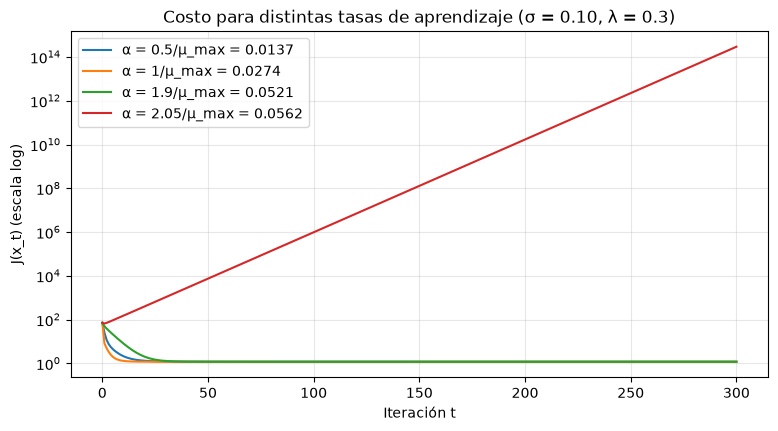

In [18]:
#Termino de regulariación
DtD = D.T @ D
#Hesiana del ejercicio 8
AtA = A7.T @ A7

#Funcion regularizadora de costo
def costo_J(x, b, lam):
    # J(x) = 1/2 (||A7 x - b||^2 + lam ||D x||^2)
    # La primera parte es la fidelidad de las mediciones, igual que en el ejercicio 8
    # La segunda es el término de regularización, que penaliza las diferencias entre píxeles vecinos
    return 0.5 * (np.linalg.norm(A7 @ x - b)**2 + lam * np.linalg.norm(D @ x)**2)

# Gradiente de la función de costo
#Gradiente del ejercicio 8 más un termino que empuja la imagen a ser más suave (menos diferencias entre píxeles vecinos)
def gradiente_J(x, b, lam):
    # ∇J(x) = A7ᵀ (A7 x - b) + lam DᵀD x
    return A7.T @ (A7 @ x - b) + lam * DtD @ x

# Gradiente descendente regularizado
def gd_regularizado(b, lam, alpha, tol=1e-6, max_iter=20000):
    x = np.zeros(A7.shape[1])                                  # x0 = 0 como pide el enunciado
    costos = [costo_J(x, b, lam)]
    errores = [np.linalg.norm(x - x_v_fantoma) / norma_fantoma]  # se registra para el inciso G

    for t in range(max_iter):
        g = gradiente_J(x, b, lam)
        if np.linalg.norm(g) < tol:                            # Frena por norma del gradiente, no usa el fantoma
            break
        x = x - alpha * g
        costos.append(costo_J(x, b, lam))
        errores.append(np.linalg.norm(x - x_v_fantoma) / norma_fantoma) 

    return x, np.array(costos), np.array(errores)


# Evaluación de tasas de aprendizaje (con sigma = 0.10, lambda = 0.3)
# La Hessiana de J es A7ᵀA7 + lambda DᵀD(se obtiene derivando el gradiente)
# El límite de estabilidad es 2 / (su mayor autovalor) como en el ejercicio 8
lam_prueba = 0.3
mu_max_prueba = np.linalg.eigvalsh(AtA + lam_prueba * DtD).max()
print(f"lambda = {lam_prueba}: mu_max = {mu_max_prueba:.3f}, 2/mu_max = {2 / mu_max_prueba:.4f}\n")

fig, ax = plt.subplots(figsize=(9, 4.5))
for f in [0.5, 1, 1.9, 2.05]:               #factores menores a 2 dentro del intervalo, mayores a 2 fuera del intervalo
    a = f / mu_max_prueba
    _, costos, _ = gd_regularizado(mediciones[0.10], lam_prueba, a, tol=0, max_iter=300)
    ax.semilogy(costos, label=f'α = {f}/μ_max = {a:.4f}')
    print(f"alpha = {a:.4f}: costo tras 300 iteraciones = {costos[-1]:.4g}")
ax.set_xlabel('Iteración t')
ax.set_ylabel('J(x_t) (escala log)')
ax.set_title('Costo para distintas tasas de aprendizaje (σ = 0.10, λ = 0.3)')
ax.legend()
ax.grid(alpha=0.3)
plt.savefig('figuras/ejercicio_09f.png', dpi=150, bbox_inches='tight')
plt.show()

In [19]:
# Se corre gradiente descendiente para cada combinación de sigma y lambda
resultados = {}
for sigma in sigmas:
    for lam in lambdas:
        #tasa de aprendizaje dentro del intervalo de estabilidad (0, 2/mu_max)
        mu_max = np.linalg.eigvalsh(AtA + lam * DtD).max()
        alpha = 1 / mu_max
        x, costos, errores = gd_regularizado(mediciones[sigma], lam, alpha)
        # Se guarda todo lo que se necesita en los incisos siguientes
        resultados[(sigma, lam)] = {
            'x': x,                   # vector reconstruido
            'costos': costos, 
            'errores': errores, 
            'alpha': alpha,
            'iter': len(costos) - 1,  # -1 porque incluye el valor inicial
            'error': errores[-1],     # error relativo final
            'residuo': np.linalg.norm(A7 @ x - mediciones[sigma]),  # ||A7 x - b_sigma||
        }

print(f"{'sigma':<7}{'lambda':<8}{'alpha':>8}{'iter':>7}{'error rel.':>12}{'||r||':>9}")
for (sigma, lam), r in resultados.items():
    print(f"{sigma:<7}{lam:<8}{r['alpha']:>8.4f}{r['iter']:>7}{r['error']:>12.4f}{r['residuo']:>9.3f}")

sigma  lambda     alpha   iter  error rel.    ||r||
0      0         0.0274    754      0.0000    0.000
0      0.1       0.0274    489      0.0423    0.201
0      0.3       0.0274    295      0.0972    0.504
0      1         0.0274    134      0.2000    1.159
0.1    0         0.0274    781      0.1626    0.585
0.1    0.1       0.0274    495      0.1383    0.628
0.1    0.3       0.0274    286      0.1384    0.807
0.1    1         0.0274    133      0.2071    1.370
0.2    0         0.0274    850      0.3251    1.170
0.2    0.1       0.0274    540      0.2693    1.203
0.2    0.3       0.0274    311      0.2310    1.340
0.2    1         0.0274    132      0.2427    1.813



Al derivar el gradiente $\nabla J$, la Hessiana de $J$ resulta $A_7^TA_7 + \lambda D^TD$, que también es constante y simétrica. Por lo tanto, se aplica el mismo análisis del Ejercicio 8c, pero con el mayor autovalor de esta nueva Hessiana. En este caso, ese autovalor casi no cambia con $\lambda$ (≈ 36.46 para todos los valores probados), así que el intervalo de tasas estables es prácticamente el mismo que en el Ejercicio 8. En el gráfico se probaron distintas tasas para $\sigma = 0.10$ y $\lambda = 0.3$: con $\alpha < 2/\mu_{\max}$ el costo baja de forma estable, y con $\alpha = 2.05/\mu_{\max}$ diverge. Se eligió $\alpha = 1/\mu_{\max}$ para cada $\lambda$, que está dentro del intervalo con margen.

El algoritmo se detiene cuando la norma del gradiente es menor que $10^{-6}$ (el costo ya no puede bajar más) o al llegar a 20000 iteraciones. El error respecto del fantoma se registra en cada iteración para el inciso g, pero no se usa para decidir cuándo parar, porque en una tomografía real el fantoma no se conoce. En todos los casos el criterio se cumplió antes del máximo de iteraciones, y con $\lambda$ más grande hicieron falta menos iteraciones.

#### g) Registrar durante las iteraciones el error relativo $e_t = \|x_t - x_{\text{fantoma}}\| / \|x_{\text{fantoma}}\|$. Para cada nivel de ruido, graficar $e_t$ en función de las iteraciones para los distintos valores de $\lambda$.

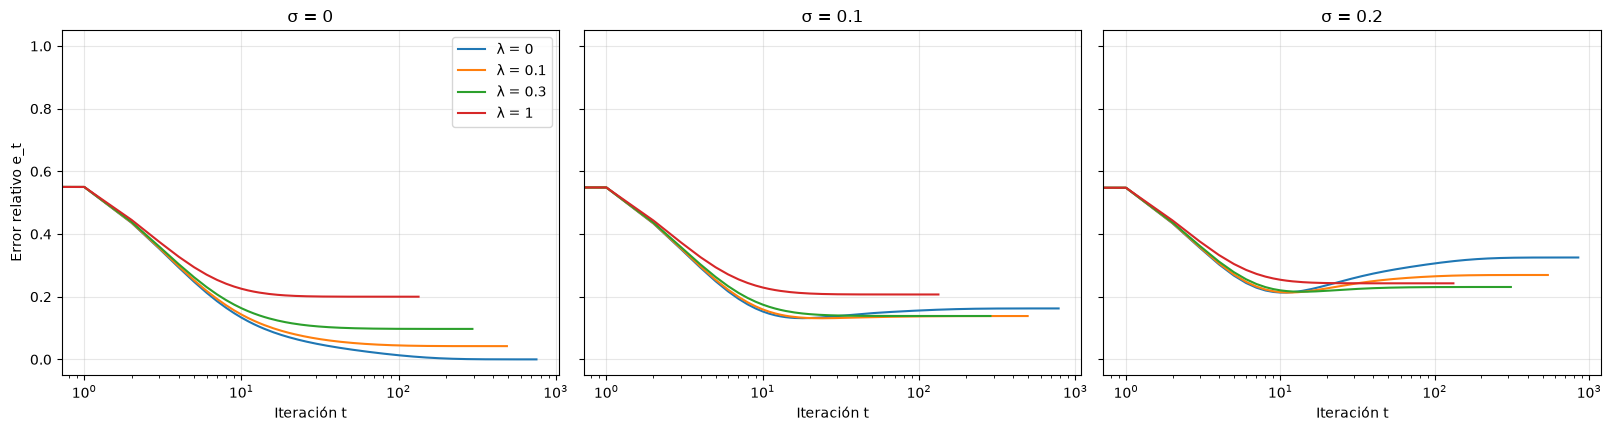

In [20]:
#Grafico de errores relativos para cada combinación de sigma y lambda
# Comparten el eje vertical para poder compara los errores entre sigmas y ver el efecto de la regularización
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True, layout='constrained')
for ax, sigma in zip(axes, sigmas):
    for lam in lambdas:
        ax.plot(resultados[(sigma, lam)]['errores'], label=f'λ = {lam}')
    ax.set_title(f'σ = {sigma}')
    ax.set_xlabel('Iteración t')
    ax.set_xscale('log')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Error relativo e_t')
axes[0].legend()
plt.savefig('figuras/ejercicio_09g.png', dpi=150, bbox_inches='tight')
plt.show()

En los tres gráficos el error arranca en el mismo valor (≈ 0.55, que corresponde a $x_0 = 0$) y baja en las primeras iteraciones. Después, el comportamiento depende del ruido

- **Sin ruido ($\sigma = 0$):** el error baja todo el tiempo. Con $\lambda = 0$ llega prácticamente a cero, y cuanto mayor es $\lambda$, más alto es el error final.
- **Con ruido ($\sigma = 0.10$ y $0.20$):** con $\lambda = 0$ (curva azul), el error baja hasta un mínimo y después vuelve a subir hasta estabilizarse en un valor más alto (≈ 0.16 y ≈ 0.33).Pero con $\lambda = 0.1$ y $0.3$ (naranja y verde), esa subida es menos notoria o directamente no aparece, y el error final queda más bajo. Finalmente con $\lambda = 1$ (rojo) el error baja más lento y se estabiliza en un valor alto, el comportamiente es similar al grafico sin ruido.

La subida del error con $\lambda = 0$ se explica porque el método no distingue entre la información real de las mediciones y el ruido. En las primeras iteraciones, la imagen pasa de ser negra a tener la forma general del fantoma, y el error baja. Una vez armada esa forma, lo que queda por ajustar son diferencias chicas, muchas de las cuales son ruido. Al copiarlas, la imagen se acerca cada vez más a las mediciones, pero se aleja del fantoma. Por eso el error vuelve a subir hasta el mismo valor que dio `lstsq` en el Ejercicio 6 (≈ 0.163 para $\sigma = 0.10$). Es lo mismo que pasa en el Ejercicio 5, visto a lo largo de las iteraciones, el residuo baja todo el tiempo, pero eso no garantiza que la imagen se parezca a la real.

Con $\lambda > 0$, el método minimiza una función que además penaliza las diferencias entre píxeles vecinos, por lo que su punto final es una imagen que explica las mediciones sin copiar los saltos producidos por el ruido. Por eso, con $\lambda = 0.1$ y $0.3$, el error casi no vuelve a subir y termina más bajo.

#### h) Organizar las reconstrucciones finales en una grilla: cada fila debe corresponder a un valor de $\sigma$ y cada columna, a un valor de $\lambda$. Utilizar la misma escala de color en todas las imágenes, sin ajustar automáticamente los límites de cada panel, e indicar el error relativo sobre cada reconstrucción.

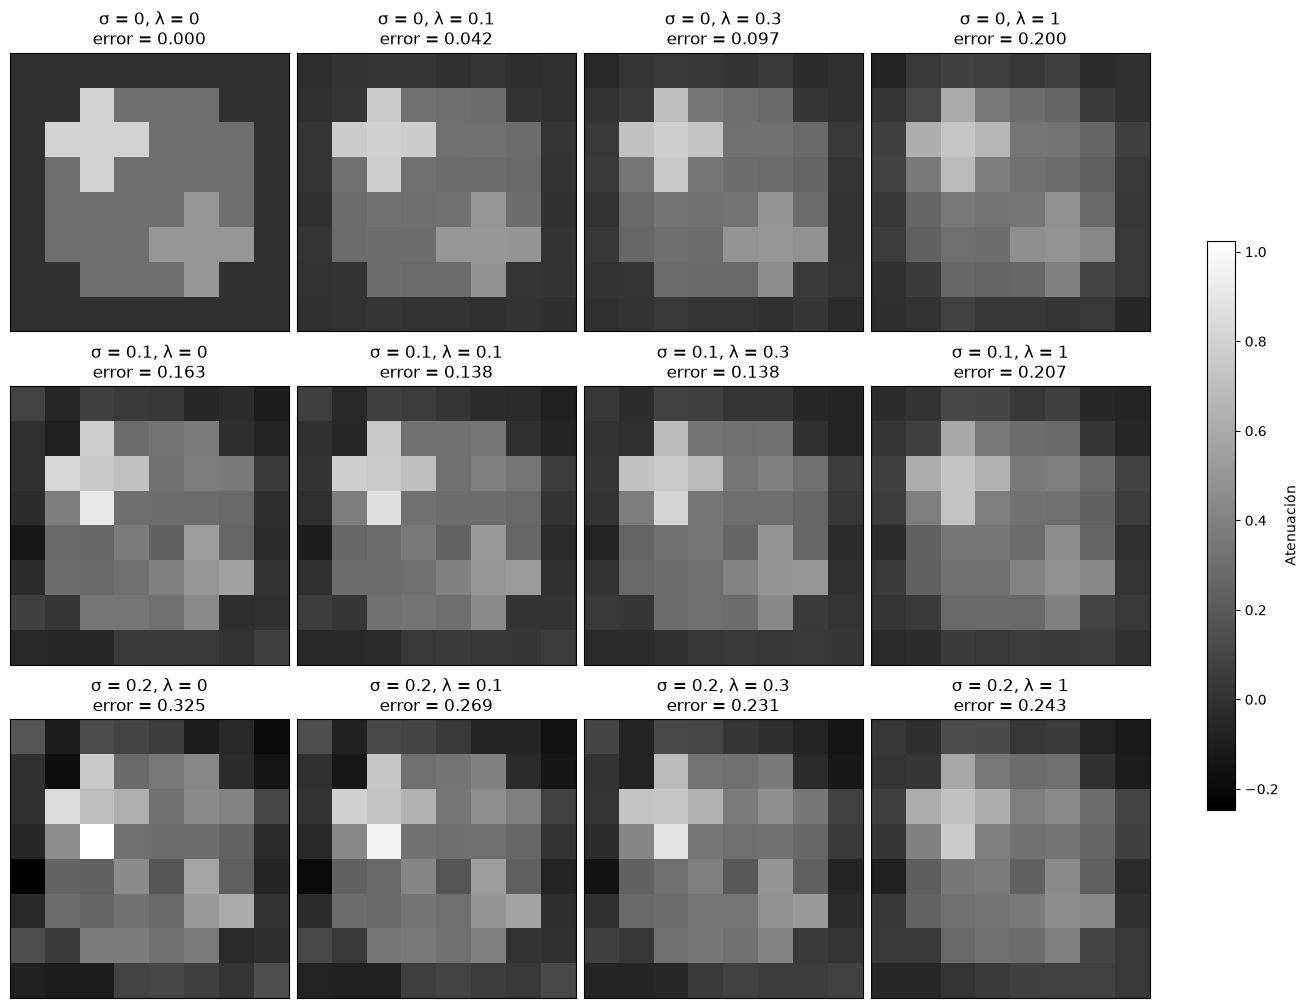

In [21]:
#Se calcula el minimo y máximo de todos los valores de x para que todas las imágenes compartan la misma escala de grises
todas = [r['x'] for r in resultados.values()]
vmin = min(x.min() for x in todas)
vmax = max(x.max() for x in todas)

# Se muestran las imágenes reconstruidas para cada combinación de sigma y lambda
# Filas = sigmas, columnas = lambdas
fig, axes = plt.subplots(len(sigmas), len(lambdas), figsize=(13, 10), layout='constrained')
for fila, sigma in enumerate(sigmas):
    for col, lam in enumerate(lambdas):
        r = resultados[(sigma, lam)]
        ax = axes[fila, col]
        im = ax.imshow(r['x'].reshape(8, 8), cmap='gray', vmin=vmin, vmax=vmax)  # vector reconstruido como imagen 8x8
        ax.set_title(f"σ = {sigma}, λ = {lam}\nerror = {r['error']:.3f}")       # Error relativo sobre cada imagen reconstruida
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.6, label='Atenuación')
plt.savefig('figuras/ejercicio_09h.png', dpi=150, bbox_inches='tight')
plt.show()

Todas las imágenes se graficaron con la misma escala de color, por lo que un mismo tono representa el mismo valor en todos los paneles. Las filas corresponden a los niveles de ruido ($\sigma = 0,\ 0.10,\ 0.20$) y las columnas, a las intensidades de regularización ($\lambda = 0,\ 0.1,\ 0.3,\ 1$). Sobre cada imagen se indica su error relativo respecto del fantoma.

- **Sin ruido (primera fila):** con $\lambda = 0$ la reconstrucción es igual al fantoma (error ≈ 0). Al aumentar $\lambda$ la imagen se vuelve cada vez más borrosa, los bordes se suavizan y las cruces pierden contraste, por lo que el error crece (0.042, 0.097 y 0.200). Como no hay ruido que eliminar, la regularización solo empeora la imagen.

- **Con ruido (segunda y tercera fila):** con $\lambda = 0$ aparecen píxeles con valores muy distintos a sus vecinos, algunos negativos y otros más altos que 0.8. Esto es un efecto del ruido, y es más notorio con $\sigma = 0.20$ que con $\sigma = 0.10$. Con $\lambda = 0.1$ y $0.3$ esas variaciones se reducen y la forma del fantoma se distingue mejor, y el error baja (para $\sigma = 0.10$, de 0.163 a 0.138, para $\sigma = 0.20$, de 0.325 a 0.231 con $\lambda = 0.3$). Con $\lambda = 1$ el ruido casi desaparece, pero la imagen queda muy borrosa, se pierden los detalles y el error vuelve a subir.

Es decir, en cada fila se ve el trade off entre ruido y suavidad
- con $\lambda$ chico la imagen conserva el ruido
- con $\lambda$ demasiado grande pierde los contornos reales

la mejor reconstrucción está en un punto intermedio que depende de cuánto ruido tienen las mediciones.

#### i) Resumir los errores relativos y las normas de los residuos en una tabla o mapa de calor cuyos ejes sean $\sigma$ y $\lambda$. Para cada nivel de ruido, identificar qué valor de $\lambda$ produjo el menor error.

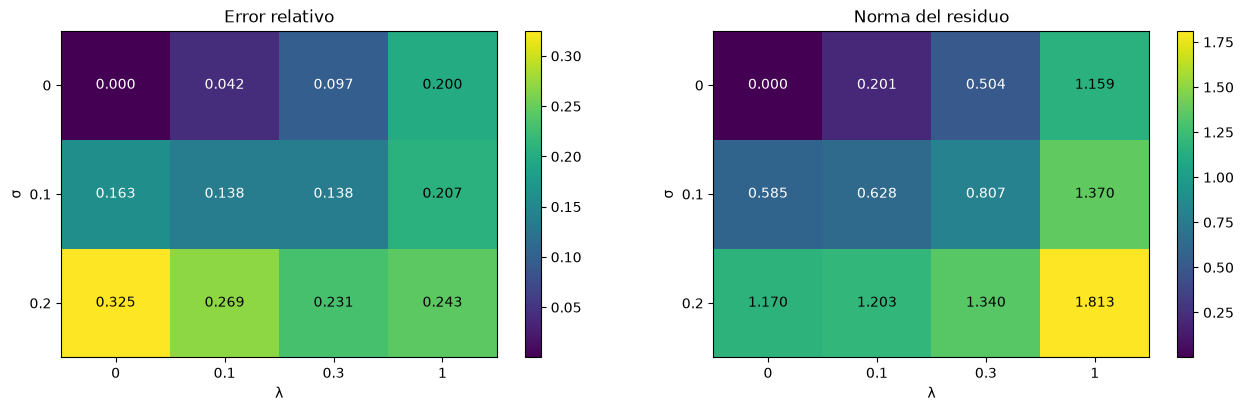

sigma = 0: menor error con lambda = 0 (error = 0.0000)
sigma = 0.1: menor error con lambda = 0.1 (error = 0.1383)
sigma = 0.2: menor error con lambda = 0.3 (error = 0.2310)


In [22]:
# Matrices de 3 x 4, fila = sigma, columna = lamda
errores = np.array([[resultados[(s, l)]['error'] for l in lambdas] for s in sigmas])
residuos = np.array([[resultados[(s, l)]['residuo'] for l in lambdas] for s in sigmas])

#Dos mapas de calor, uno para el error y otro para el residuo
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for ax, datos, titulo in zip(axes, [errores, residuos], ['Error relativo', 'Norma del residuo']):
    im = ax.imshow(datos, cmap='viridis')
    ax.set_xticks(range(len(lambdas)), [str(l) for l in lambdas])
    ax.set_yticks(range(len(sigmas)), [str(s) for s in sigmas])
    ax.set_xlabel('λ')
    ax.set_ylabel('σ')
    ax.set_title(titulo)
    for i in range(len(sigmas)):
        for j in range(len(lambdas)):
            color = 'black' if datos[i, j] > datos.max() * 0.6 else 'white'   # texto legible sobre colores claros
            ax.text(j, i, f'{datos[i, j]:.3f}', ha='center', va='center', color=color)
    fig.colorbar(im, ax=ax)
plt.savefig('figuras/ejercicio_09i.png', dpi=150, bbox_inches='tight')
plt.show()

#Para cada sigma, el lamda con menor error
for i, sigma in enumerate(sigmas):
    mejor = lambdas[np.argmin(errores[i])]
    print(f"sigma = {sigma}: menor error con lambda = {mejor} (error = {errores[i].min():.4f})")

El menor error se obtuvo con $\lambda = 0$ para $\sigma = 0$, con $\lambda = 0.1$ para $\sigma = 0.10$ (aunque $\lambda = 0.3$ da prácticamente el mismo error) y con $\lambda = 0.3$ para $\sigma = 0.20$.

El residuo, en cambio, aumenta siempre con $\lambda$, para todos los niveles de ruido. 

#### j) Analizar los resultados. ¿En qué casos la regularización mejoró la reconstrucción obtenida con $\lambda = 0$? ¿Cómo cambió el valor más conveniente de $\lambda$ al aumentar el ruido? ¿Qué efecto produjo una regularización excesiva?

**¿En qué casos la regularización mejoró la reconstrucción?** En los casos con ruido. Con $\sigma = 0.10$ el error bajó de 0.163 ($\lambda = 0$) a 0.138 ($\lambda = 0.1$), y con $\sigma = 0.20$ bajó de 0.325 a 0.231 ($\lambda = 0.3$). Esto ocurre porque el ruido produce cambios bruscos entre píxeles vecinos, que hacen crecer $\|Dx\|$. Al penalizar ese término, la reconstrucción prefiere imágenes más suaves y filtrando parte del ruido. En cambio, sin ruido la regularización empeoró la reconstrucción con cualquier $\lambda > 0$, como $A_7$ tiene rango completo, sin ruido la solución de mínimos cuadrados ya es el fantoma y suavizar solo logra alejarse de él.

**¿Cómo cambió el $\lambda$ más conveniente al aumentar el ruido?**  Aumentó, fue $0$ sin ruido, $0.1$ con $\sigma = 0.10$ y $0.3$ con $\sigma = 0.20$. Cuanto más ruido tienen las mediciones, menos conviene confiar en ellas, y por lo tanto conviene darle más importancia a la suavidad.

**¿Qué efecto produjo una regularización excesiva?** Con $\lambda = 1$ el error aumentó en todos los niveles de ruido respecto del mejor $\lambda$, y en los gráficos se ve que la imagen queda borrosa, es decir los bordes del fantoma se suavizaron y las cruces perdieron contraste. Esto ocurre porque, cuando $\lambda$ es muy grande, el término de suavidad pesa más que las mediciones, y la reconstrucción tiende a una imagen con poca variación entre vecinos (como la imagen constante del inciso b) aunque eso signifique alejarse de lo que dicen las mediciones, lo que hace que el residuo sea más alto.

En conclusión, como $\lambda$ controla el trade off entre fidelidad a las mediciones y reducción del ruido, un $\lambda$ demasiado chico deja pasar el ruido, y uno demasiado grande borra los detalles de la imagen. El valor más conveniente depende de cuánto ruido tengan las mediciones.